# UniMol embeddings

- This notebook generates embeddings across several datasets using the **UniMol** molecular embedding model
- The three datasets are the MCES dataset by Kretschmer et al (2025), a 30K subset of the ZINC database, and the Biogen ADMET dataset.
- You will need to edit the file paths in the relevant section below.

# Imports

In [4]:
import torch
from unimol_tools import UniMolRepr
import numpy as np
import pandas as pd
from tqdm.auto import tqdm
import rdkit
from rdkit import Chem
import sklearn
from sklearn.metrics.pairwise import cosine_similarity

## File paths

In [ ]:
BIOGEN_PATH  = ''
MCES_PATH    = ''
ZINC30K_PATH = ''

# Model set-up

In [2]:
model = UniMolRepr(
    data_type="molecule",
    remove_hs=False,
    use_cuda=torch.cuda.is_available(),
)

2026-11-08 20:08:24 | unimol_tools/models/unimol.py | 167 | INFO | Uni-Mol Tools | Loading pretrained weights from /home/blake/miniconda3/envs/unimol-embed/lib/python3.10/site-packages/unimol_tools/weights/mol_pre_all_h_220816.pt


In [3]:
unimol = model.model

total_params = sum(p.numel() for p in unimol.parameters())
trainable_params = sum(
    p.numel() for p in unimol.parameters()
    if p.requires_grad
)

print(f"Total parameters:     {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Total parameters:     {total_params / 1e6:.3f}M")

Total parameters:     47,331,139
Trainable parameters: 47,331,139
Total parameters:     47.331M


# MCES

In [ ]:
distances = np.load(MCES_PATH)
mces      = distances['mces']
smiles    = distances['smiles']

print(mces.shape)
print(smiles.shape)

(2012094766,)
(63437,)


In [ ]:
embeddings = model.get_repr(smiles, return_atomic_reprs=False)
np.save('MCES/UniMol MCES embeddings.npy', np.array(embeddings))

2026-06-11 10:09:06 | unimol_tools/data/conformer.py | 182 | INFO | Uni-Mol Tools | Start generating conformers...
63437it [1:17:02, 13.72it/s]
2026-06-11 11:26:10 | unimol_tools/data/conformer.py | 197 | INFO | Uni-Mol Tools | Succeeded in generating conformers for 100.00% of molecules.
2026-06-11 11:26:10 | unimol_tools/data/conformer.py | 214 | INFO | Uni-Mol Tools | Succeeded in generating 3d conformers for 96.39% of molecules.
2026-06-11 11:26:10 | unimol_tools/data/conformer.py | 223 | INFO | Uni-Mol Tools | Failed 3d conformers indices: [3, 120, 129, 1031, 1279, 1282, 1291, 1940, 2000, 2924, 3034, 4221, 4546, 4648, 4651, 4653, 4665, 4667, 5593, 5860, 6024, 6244, 6352, 7737, 7740, 7741, 8067, 8096, 8130, 8515, 8598, 8599, 8841, 9000, 9434, 9970, 11465, 11622, 12267, 13180, 13182, 13684, 13960, 15303, 15984, 16654, 17105, 17107, 18124, 18125, 18730, 20974, 21981, 22013, 22014, 22015, 22114, 22162, 22164, 22209, 22218, 22220, 22287, 22334, 22347, 22348, 22370, 22377, 22383, 22384, 

In [ ]:
# Save cosine similarities in a flattened row-major, upper triangle format.

X = np.asarray(embeddings, dtype=np.float32)
n = X.shape[0]

# Normalize rows
norms = np.linalg.norm(X, axis=1, keepdims=True)
X = X / np.clip(norms, 1e-12, None)

m = n * (n - 1) // 2

pairwise_cosine = np.memmap(
    "MCES/UniMol MCES pairwise cosines.dat",
    dtype="float32",
    mode="w+",
    shape=(m,),
)

offset = 0
chunk_size = 1000

for i_start in tqdm(range(0, n, chunk_size)):
    i_end = min(i_start + chunk_size, n)

    for i in range(i_start, i_end):
        sims = X[i] @ X[i + 1:].T
        pairwise_cosine[offset:offset + len(sims)] = sims
        offset += len(sims)

pairwise_cosine.flush()

print("Expected length:", m)
print("Written length:", offset)

100%|██████████| 64/64 [02:17<00:00,  2.16s/it]


Expected length: 2012094766
Written length: 2012094766


In [ ]:
# Save indices in a flattened row-major, upper triangle format.

n = 63437
m = n * (n - 1) // 2

pair_indices = np.memmap(
    "MCES/UniMol pairwise indices.dat",
    dtype=np.uint32,
    mode="w+",
    shape=(m, 2),
)

offset = 0

for i in tqdm(range(n - 1)):
    n_pairs = n - i - 1

    pair_indices[offset:offset + n_pairs, 0] = i
    pair_indices[offset:offset + n_pairs, 1] = np.arange(
        i + 1,
        n,
        dtype=np.uint32,
    )

    offset += n_pairs

pair_indices.flush()

print("Expected:", m)
print("Written:", offset)

100%|██████████| 63436/63436 [00:25<00:00, 2453.71it/s] 


Expected: 2012094766
Written: 2012094766


## MCES figure example

2026-11-08 20:10:57 | unimol_tools/data/conformer.py | 182 | INFO | Uni-Mol Tools | Start generating conformers...
2it [00:00, 11.73it/s]
2026-11-08 20:10:57 | unimol_tools/data/conformer.py | 197 | INFO | Uni-Mol Tools | Succeeded in generating conformers for 100.00% of molecules.
2026-11-08 20:10:57 | unimol_tools/data/conformer.py | 214 | INFO | Uni-Mol Tools | Succeeded in generating 3d conformers for 100.00% of molecules.
2026-11-08 20:10:57 | unimol_tools/tasks/trainer.py | 103 | INFO | Uni-Mol Tools | Using CPU.
100%|██████████| 1/1 [00:00<00:00,  2.57it/s]

Cosine similarity: [[0.9561786]]


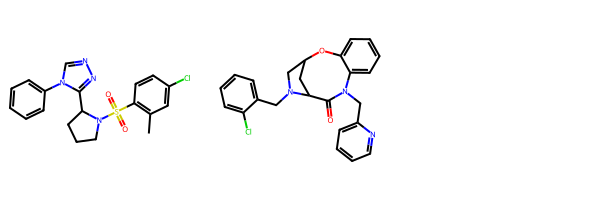

In [8]:
close_pair_a = "CC1=C(C=CC(=C1)Cl)S(=O)(=O)N2CCCC2C3=NN=CN3C4=CC=CC=C4"
close_pair_b = "C1C2CN(C1C(=O)N(C3=CC=CC=C3O2)CC4=CC=CC=N4)CC5=CC=CC=C5Cl"

close_pair_mol_a = Chem.MolFromSmiles(close_pair_a)
close_pair_mol_b = Chem.MolFromSmiles(close_pair_b)

embeddings = model.get_repr([close_pair_a, close_pair_b], return_atomic_reprs=False)
print(f"Cosine similarity: {cosine_similarity(embeddings[0].reshape(1, -1), embeddings[1].reshape(1, -1))}")

Chem.Draw.MolsToGridImage([close_pair_mol_a, close_pair_mol_b])

2026-11-08 20:11:56 | unimol_tools/data/conformer.py | 182 | INFO | Uni-Mol Tools | Start generating conformers...
2it [00:00, 25.12it/s]
2026-11-08 20:11:56 | unimol_tools/data/conformer.py | 197 | INFO | Uni-Mol Tools | Succeeded in generating conformers for 100.00% of molecules.
2026-11-08 20:11:56 | unimol_tools/data/conformer.py | 214 | INFO | Uni-Mol Tools | Succeeded in generating 3d conformers for 100.00% of molecules.
2026-11-08 20:11:56 | unimol_tools/tasks/trainer.py | 103 | INFO | Uni-Mol Tools | Using CPU.
100%|██████████| 1/1 [00:00<00:00,  1.80it/s]

Cosine similarity: [[0.58131254]]


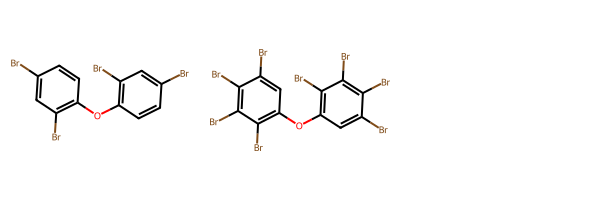

In [9]:
distant_pair_a = "C1=CC(=C(C=C1Br)Br)OC2=C(C=C(C=C2)Br)Br"
distant_pair_b = "C1=C(C(=C(C(=C1Br)Br)Br)Br)OC2=CC(=C(C(=C2Br)Br)Br)Br"

distant_pair_mol_a = Chem.MolFromSmiles(distant_pair_a)
distant_pair_mol_b = Chem.MolFromSmiles(distant_pair_b)

embeddings = model.get_repr([distant_pair_a, distant_pair_b], return_atomic_reprs=False)
print(f"Cosine similarity: {cosine_similarity(embeddings[0].reshape(1, -1), embeddings[1].reshape(1, -1))}")

Chem.Draw.MolsToGridImage([distant_pair_mol_a, distant_pair_mol_b])

# Biogen

In [ ]:
biogen     = pd.read_csv(BIOGEN_PATH)
smiles     = biogen['SMILES'].tolist()
embeddings = model.get_repr(smiles, return_atomic_reprs=False)
np.save('Biogen/UniMol Biogen embeddings.npy', embeddings)

2026-07-01 10:48:29 | unimol_tools/data/conformer.py | 182 | INFO | Uni-Mol Tools | Start generating conformers...
3521it [00:23, 149.45it/s]
2026-07-01 10:48:52 | unimol_tools/data/conformer.py | 197 | INFO | Uni-Mol Tools | Succeeded in generating conformers for 100.00% of molecules.
2026-07-01 10:48:52 | unimol_tools/data/conformer.py | 214 | INFO | Uni-Mol Tools | Succeeded in generating 3d conformers for 99.97% of molecules.
2026-07-01 10:48:52 | unimol_tools/data/conformer.py | 223 | INFO | Uni-Mol Tools | Failed 3d conformers indices: [2945]
2026-07-01 10:48:53 | unimol_tools/tasks/trainer.py | 103 | INFO | Uni-Mol Tools | Using CPU.
100%|██████████| 111/111 [05:47<00:00,  3.14s/it]


# ZINC

In [ ]:
# ZINC file contains randomly sampled molecules. 
data       = pd.read_csv(ZINC30K_PATH)[:30000]
smiles     = data['SMILES'].tolist()
embeddings = model.get_repr(smiles, return_atomic_reprs=False)
np.save('zINC/UniMol ZINC30K embeddings.npy', embeddings)